# ราคารถมือสอง — Random Forest (เวอร์ชัน 4, โมเดลพื้นฐาน)
- ข้อมูล: `merged_min50.csv` (รถทุกรุ่นมีอย่างน้อย 50 คัน) การตรวจข้อมูล การแบ่ง train/val/test (80 / 10 / 10 แบบ stratified ตามรุ่น) และ one-hot **เหมือนกันทุกตัวอักษร** กับ notebook MLR4 / DT4 / RF4 / XGB4
- ตัวแปรที่ใช้ **ไม่ได้กำหนดเอง** แต่เลือกจาก train ในหัวข้อ 5 (กรองตัวซ้ำซ้อน + วิธีเลือกของโมเดลนี้) และใช้ cross-validation 5 fold
- **ทำนายราคาตรง ๆ** (ไม่แปลง log) และวัดผลบนราคาจริง
- โมเดลพื้นฐาน = `RandomForestRegressor` **ค่า default ทั้งหมด** (ไม่จูน) ไม่ต้องทดสอบ assumption แบบ MLR
- notebook นี้รันจากบนลงล่างได้เอง ใช้แค่ไฟล์ CSV

> ต้อง mount Google Drive ก่อนรัน

## 0. Import และค่าตั้งต้น
รวมค่าที่ใช้ทั้ง notebook ไว้ที่เดียว จะได้แก้ง่าย (สัดส่วน train/val/test ก็อยู่ตรงนี้)

In [1]:
import os
import time
import hashlib
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.model_selection import train_test_split, KFold
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
import sklearn
from sklearn.ensemble import RandomForestRegressor

DATA_PATH = "/content/drive/MyDrive/Project/cardb/merged_min50.csv"
# ใช้รันในเครื่อง: ถ้าไม่เจอ path ของ Drive ให้ใช้ไฟล์ในเครื่องแทน (บน Colab ไม่มีผล)
if not os.path.exists(DATA_PATH):
    DATA_PATH = r"D:\Claude\project_car_used\data\newdata\cleaned\merged_min50.csv"

SEED = 99            # เลขสุ่มคงที่ รันกี่ครั้งก็ได้ผลเหมือนเดิม
CURRENT_YEAR = 2026  # ปีที่เก็บข้อมูล ใช้คำนวณอายุรถ
TRAIN_SIZE = 0.8
VAL_SIZE = 0.1
TEST_SIZE = 0.1

EXPECTED_SHA256 = "1a817cf9acc35c2ee244117c17a6ae93bbe5c33ccbe54fd63c47dc0f22ce88b9"   # ลายนิ้วมือของไฟล์ข้อมูล (ตัด \r ออกก่อนคำนวณ)
REDUNDANT_MAX = 0.95   # คู่ตัวแปรที่สัมพันธ์กันตั้งแต่ค่านี้ขึ้นไป ถือว่าซ้ำซ้อน
TOL = 0.02             # ตัดตัวแปรได้ ถ้า CV MAE แย่ลงไม่เกิน 2%
N_FOLDS = 5            # จำนวน fold ของ cross-validation

NUM_COLS = ["engine_capacity", "mileage", "car_age"]                              # ตัวแปรตัวเลข
CAT_COLS = ["brand", "model", "car_type", "fuel_type", "gear_type", "color"]      # ตัวแปรกลุ่ม

pd.set_option("display.width", 200, "display.max_columns", 50)
# คำเตือนภายในของ scikit-learn/joblib ตอนเรียก RandomForest แบบหลาย core (ไม่เกี่ยวกับข้อมูลหรือผลลัพธ์) ซ่อนไว้ไม่ให้ท่วมผลลัพธ์
warnings.filterwarnings("ignore", message=".*sklearn.utils.parallel.delayed.*")

## 1. โหลดข้อมูล

In [2]:
df = pd.read_csv(DATA_PATH, encoding="utf-8-sig")

## 2. ตรวจคุณภาพข้อมูล (data check) — ทุกโมเดลตรวจชุดเดียวกัน
ข้อมูลชุดนี้ทำความสะอาดมาแล้ว ขั้นนี้ **แค่ตรวจและรายงาน** ไม่ได้เรียนรู้อะไรจากข้อมูล ไม่แก้ข้อมูล
- ตรวจ **sha256** ของไฟล์ (ลายนิ้วมือของไฟล์) ว่าเป็นไฟล์เวอร์ชันเดียวกับที่ใช้ทำผลทั้งหมด ถ้าไม่ตรงโค้ดจะหยุดทันที (ตัดตัวอักษร `\r` ออกก่อน เพื่อให้ได้ค่าเดียวกันทั้งบน Windows และ Colab)
- ตรวจขนาดตาราง ชนิดข้อมูล (dtypes) ค่าว่าง แถวซ้ำ ค่าต่ำสุด/สูงสุดของตัวเลข
- ตรวจกฎพื้นฐาน: ราคา ไมล์ เครื่องยนต์ต้องมากกว่า 0 และปีรถต้องไม่เกินปีที่เก็บข้อมูล
- ดูจำนวนค่า (levels) ของตัวแปรกลุ่มแต่ละตัว และจำนวนรถต่อรุ่น
- รายงานเพิ่ม (ไม่แก้): สัดส่วนไมล์ = 2,500 กม. (ค่ากลางของช่วง "ต่ำกว่า 5,000" ที่บางแหล่งใช้แทนไมล์ที่ไม่ทราบ) และ กม./ปี สูงสุด

In [3]:
with open(DATA_PATH, "rb") as f:
    file_hash = hashlib.sha256(f.read().replace(b"\r", b"")).hexdigest()
assert file_hash == EXPECTED_SHA256, f"ไฟล์ข้อมูลไม่ตรงกับเวอร์ชันที่ใช้ทำผล (sha256 ที่ได้ = {file_hash})"
print("sha256 ตรงกับไฟล์ที่คาดไว้:", file_hash[:16], "...")

print("\nshape:", df.shape)
print("\ndtypes:"); print(df.dtypes.to_string())
print("\nค่าว่างต่อคอลัมน์:"); print(df.isna().sum().to_string())
print("\nแถวซ้ำทั้งแถว:", int(df.duplicated().sum()))
print("\nค่าต่ำสุด / สูงสุดของตัวเลข:")
print(df.select_dtypes("number").agg(["min", "max"]).T.to_string())

assert df.notna().all().all(), "มีค่าว่าง"
assert (df["price"] > 0).all(), "มีราคาที่ไม่เป็นบวก"
assert (df["mileage"] > 0).all(), "มีไมล์ที่ไม่เป็นบวก"
assert (df["engine"] > 0).all(), "มีเครื่องยนต์ที่ไม่เป็นบวก"
assert (df["year"] <= CURRENT_YEAR).all(), "มีปีรถที่เกินปีที่เก็บข้อมูล"
print("\nผ่าน: ไม่มีค่าว่าง, price / mileage / engine > 0, year <= ปีที่เก็บข้อมูล ทุกแถว")

print("\nจำนวน levels ของตัวแปรกลุ่ม:")
print(df[["brand", "model", "car_type", "fuel", "gear", "color"]].nunique().to_string())
per_model = df.groupby(["brand", "model"]).size()
print(f"\nรถต่อรุ่น: น้อยสุด {per_model.min()} | มัธยฐาน {per_model.median():.0f} | มากสุด {per_model.max()} ({len(per_model)} รุ่น)")

# รายงานเพิ่ม (ไม่แก้ข้อมูล)
km_per_year = df["mileage"] / (CURRENT_YEAR - df["year"]).clip(lower=1)
print(f"\nไมล์ = 2,500 กม.: {(df['mileage'] == 2500).sum():,} แถว ({(df['mileage'] == 2500).mean():.1%})")
print(f"กม./ปี สูงสุด: {km_per_year.max():,.0f}")

sha256 ตรงกับไฟล์ที่คาดไว้: 1a817cf9acc35c2e ...

shape: (50540, 10)

dtypes:
brand         str
model         str
year        int64
price       int64
mileage     int64
engine      int64
gear          str
fuel          str
color         str
car_type      str

ค่าว่างต่อคอลัมน์:
brand       0
model       0
year        0
price       0
mileage     0
engine      0
gear        0
fuel        0
color       0
car_type    0

แถวซ้ำทั้งแถว: 0

ค่าต่ำสุด / สูงสุดของตัวเลข:
           min      max
year      2006     2026
price    27900  2000000
mileage    102   300000
engine    1000     3600

ผ่าน: ไม่มีค่าว่าง, price / mileage / engine > 0, year <= ปีที่เก็บข้อมูล ทุกแถว

จำนวน levels ของตัวแปรกลุ่ม:
brand        20
model       118
car_type      7
fuel          3
gear          2
color        20

รถต่อรุ่น: น้อยสุด 50 | มัธยฐาน 200 | มากสุด 2988 (118 รุ่น)

ไมล์ = 2,500 กม.: 2,640 แถว (5.2%)
กม./ปี สูงสุด: 60,000


## 3. เตรียมแถวข้อมูล
- เปลี่ยนชื่อคอลัมน์ให้ตรงกับชื่อที่ใช้ทุก notebook (`engine` -> `engine_capacity`, `fuel` -> `fuel_type`, `gear` -> `gear_type`)
- สร้าง `car_age = ปีที่เก็บข้อมูล - year` แล้วตัดคอลัมน์ `year` ทิ้ง เพราะข้อมูลซ้ำกันเป๊ะ ๆ (`year = 2026 - car_age`)
- ไม่ตัดแถวเพิ่ม ใช้ตามไฟล์ `merged_min50.csv` (ทำความสะอาดและกรองรุ่นที่มีรถน้อยกว่า 50 คันมาแล้ว)

In [4]:
df = df.rename(columns={"engine": "engine_capacity", "fuel": "fuel_type", "gear": "gear_type"})
df["car_age"] = CURRENT_YEAR - df["year"]
df = df.drop(columns="year")
assert df[NUM_COLS + CAT_COLS + ["price"]].notna().all().all()
print(df.shape)
df.head()

(50540, 10)


,brand,model,price,mileage,engine_capacity,gear_type,fuel_type,color,car_type,car_age
0,HONDA,CR-V,1129000,42500,2000,Automatic,Hybrid,Grey,SUV,2
1,TOYOTA,VELLFIRE,999000,147500,2500,Automatic,Hybrid,White,MPV,11
2,BMW,530E,899000,107500,2000,Automatic,Hybrid,White,Sedan,5
3,HONDA,HR-V,759000,97500,1500,Automatic,Hybrid,Grey,SUV,3
4,TOYOTA,YARIS CROSS,749000,32500,1500,Automatic,Hybrid,Grey,SUV,2


## 4. แบ่ง train / val / test (80 / 10 / 10)
- `train` ใช้สอนโมเดล (และเลือกตัวแปร), `val` ใช้ตรวจโมเดลระหว่างทำ, `test` ใช้วัดผลสุดท้ายครั้งเดียว
- แบ่งแบบ **stratified ตาม (ยี่ห้อ, รุ่น)**: รถแต่ละรุ่นถูกแบ่งเข้าทั้ง 3 ชุดตามสัดส่วน 80 / 10 / 10 ของรุ่นนั้นเอง ทุกรุ่นจึงอยู่ครบทั้ง train, val และ test (รุ่นที่น้อยสุดมี 50 คัน ได้ราว 40 / 5 / 5 คัน)
- แบ่ง 2 ขั้น: (1) แยก train 80% ออก (2) แบ่ง 20% ที่เหลือครึ่งต่อครึ่งเป็น val กับ test ทั้งสองขั้นใช้ `stratify` และ `random_state = SEED`
- **ทุกโมเดล (MLR / DT / RF / XGB) ใช้โค้ดแบ่งชุดนี้เหมือนกันทุกตัวอักษร** จะได้ชุดข้อมูลเดียวกัน เทียบกันได้ตรง ๆ (เซลล์ถัดไปพิมพ์ลายนิ้วมือของ index ไว้เทียบข้าม notebook)

In [5]:
# ขั้น 1: แยก train 80% (stratified ตาม ยี่ห้อ + รุ่น)
model_key = df["brand"] + "|" + df["model"]
train, temp = train_test_split(df, train_size=TRAIN_SIZE, stratify=model_key, random_state=SEED)

# ขั้น 2: แบ่งส่วนที่เหลือครึ่งต่อครึ่ง เป็น val กับ test (stratified เหมือนเดิม)
val, test = train_test_split(temp, test_size=TEST_SIZE / (VAL_SIZE + TEST_SIZE),
                             stratify=model_key.loc[temp.index], random_state=SEED)

print("train / val / test:", len(train), len(val), len(test))

train / val / test: 40432 5054 5054


In [6]:
# ตรวจว่าทุกรุ่นอยู่ครบทั้ง 3 ชุด และสัดส่วนใกล้ 80 / 10 / 10
counts = pd.concat({"train": model_key.loc[train.index].value_counts(),
                    "val": model_key.loc[val.index].value_counts(),
                    "test": model_key.loc[test.index].value_counts()}, axis=1).fillna(0).astype(int)
counts["total"] = counts.sum(axis=1)
assert (counts[["train", "val", "test"]] > 0).all().all(), "มีรุ่นที่หายไปจากบางชุด"
print(f"ทุกรุ่น ({len(counts)} รุ่น) อยู่ครบทั้ง train, val และ test")

share = counts[["train", "val", "test"]].div(counts["total"], axis=0)
print("\nสัดส่วนของแต่ละรุ่นในแต่ละชุด (ควรใกล้ 0.8 / 0.1 / 0.1):")
print(share.agg(["min", "max"]).round(3).to_string())
print("\nรุ่นที่สัดส่วนต่างจากเป้ามากที่สุด 5 รุ่น:")
off = (share - pd.Series({"train": TRAIN_SIZE, "val": VAL_SIZE, "test": TEST_SIZE})).abs().max(axis=1).sort_values(ascending=False)
print(pd.concat([counts.loc[off.index[:5]], off.head(5).rename("max |ต่างจากเป้า|").round(3)], axis=1).to_string())

# ลายนิ้วมือของการแบ่ง: ทุก notebook ต้องได้ค่าเดียวกัน
fingerprint = hashlib.md5(",".join(f"{name}:{','.join(map(str, sorted(part.index)))}"
                                   for name, part in (("train", train), ("val", val), ("test", test))).encode()).hexdigest()
print("\nลายนิ้วมือของการแบ่ง (md5 ของ index):", fingerprint)

ทุกรุ่น (118 รุ่น) อยู่ครบทั้ง train, val และ test

สัดส่วนของแต่ละรุ่นในแต่ละชุด (ควรใกล้ 0.8 / 0.1 / 0.1):
     train    val   test
min  0.792  0.089  0.093
max  0.806  0.107  0.113

รุ่นที่สัดส่วนต่างจากเป้ามากที่สุด 5 รุ่น:


                    train  val  test  total  max |ต่างจากเป้า|
MG|VS HEV              42    5     6     53              0.013
VOLVO|XC90             50    6     7     63              0.011
MERCEDES-BENZ|S300     43    5     6     54              0.011
NISSAN|SYLPHY          45    5     6     56              0.011
TOYOTA|PRIUS           45    5     6     56              0.011

ลายนิ้วมือของการแบ่ง (md5 ของ index): ab8dee837041fc111cf8b997eec7d2b1


## 5. เลือกตัวแปร (variable selection) — ใช้เฉพาะ train
ไม่ได้ใส่ตัวแปรทุกตัวเข้าโมเดลตรง ๆ แต่ให้ข้อมูลช่วยเลือก ทำ 2 ชั้น โดยใช้ **train เท่านั้น** (val/test ไม่ถูกแตะ):

| ชั้น | ทำอะไร |
|---|---|
| 1. กรองตัวแปรซ้ำซ้อน (redundancy filter) | ดูทุกคู่ตัวแปร ถ้าสัมพันธ์กันเกิน 0.95 ถือว่าซ้ำกัน ตัดออกหนึ่งตัวในคู่ |
| 2. เลือกตามวิธีของโมเดลนั้น | MLR: GVIF + ตัดแบบถอยหลัง (backward elimination) ด้วย F-test และ CV MAE / ต้นไม้: permutation importance + ตัดแบบถอยหลัง |

### 5.1 ชั้น 1: กรองความซ้ำซ้อน
วัดความสัมพันธ์ของแต่ละคู่ให้อยู่ในช่วง 0-1 เหมือนกันหมด จะได้ใช้เกณฑ์เดียว (`REDUNDANT_MAX` = 0.95):
- **ตัวเลข x ตัวเลข:** |Pearson r|
- **กลุ่ม x กลุ่ม:** Cramér's V (แบบปรับ bias ของ Bergsma 2013) V ไม่บอกทิศทาง จึงใช้ **Theil's U** ช่วย: U(a|b) = สัดส่วนความไม่แน่นอนของ a ที่ b อธิบายได้ ถ้า U(a|b) ≈ 1 แปลว่า b มีข้อมูลของ a อยู่แล้ว ตัด a (ตัวที่หยาบกว่า)
- **ตัวเลข x กลุ่ม:** correlation ratio η (รากของสัดส่วนความแปรปรวนของตัวเลขที่กลุ่มอธิบายได้)

**ใครโดนตัดอะไร:** คู่ที่เกือบซ้ำ (>= 0.95 แต่ไม่ถึง 1) เป็นปัญหาของ **MLR เท่านั้น** เพราะตัวแปรที่สัมพันธ์กันทำให้ค่าสัมประสิทธิ์ไม่นิ่ง (เช่น `brand` ถูก `model` กำหนดได้ทั้งหมด dummy ของ brand จึงเป็นผลบวกของ dummy ของ model พอดี ทำให้ OLS คำนวณไม่ได้) ต้นไม้ไม่เดือดร้อน และตัวแปรที่หยาบกว่า (เช่น `brand`) ยังช่วยต้นไม้ได้ ต้นไม้จึงตัดเฉพาะตัวที่ซ้ำกัน **เป๊ะ** (|r| = 1) แล้วให้ชั้น 2 ตัดสินส่วนที่เหลือ

In [7]:
def entropy(x):
    p = x.value_counts(normalize=True)
    return -(p * np.log(p)).sum()


def theil_u(a, b):
    """U(a|b): สัดส่วน entropy ของ a ที่ b อธิบายได้ (1 = b กำหนด a ได้หมด)"""
    return 1 - sum(len(g) / len(a) * entropy(g) for _, g in a.groupby(b)) / entropy(a)


def cramers_v(a, b):
    """Cramér's V แบบปรับ bias (Bergsma 2013)"""
    t = pd.crosstab(a, b)
    n = t.values.sum()
    r, k = t.shape
    phi2 = max(0, stats.chi2_contingency(t, correction=False)[0] / n - (k - 1) * (r - 1) / (n - 1))
    r_corr, k_corr = r - (r - 1) ** 2 / (n - 1), k - (k - 1) ** 2 / (n - 1)
    return np.sqrt(phi2 / min(k_corr - 1, r_corr - 1))


def eta(x, group):
    """correlation ratio: ตัวเลข x ถูกอธิบายด้วยกลุ่ม group ได้เท่าไร"""
    m = x.mean()
    return np.sqrt(sum(len(s) * (s.mean() - m) ** 2 for _, s in x.groupby(group)) / ((x - m) ** 2).sum())


rows = []
for i, a in enumerate(NUM_COLS):
    for b in NUM_COLS[i + 1:]:
        rows.append(dict(a=a, b=b, measure="|r|", value=abs(train[a].corr(train[b]))))
for i, a in enumerate(CAT_COLS):
    for b in CAT_COLS[i + 1:]:
        rows.append(dict(a=a, b=b, measure="Cramér's V", value=cramers_v(train[a], train[b]),
                         U_a_given_b=theil_u(train[a], train[b]), U_b_given_a=theil_u(train[b], train[a])))
for a in NUM_COLS:
    for b in CAT_COLS:
        rows.append(dict(a=a, b=b, measure="η", value=eta(train[a], train[b])))
pairs = pd.DataFrame(rows).sort_values("value", ascending=False)
pairs["redundant"] = pairs["value"] >= REDUNDANT_MAX
pairs.round(3).head(15)

,a,b,measure,value,U_a_given_b,U_b_given_a,redundant
3,brand,model,Cramér's V,0.999,1.000,0.536,True
8,model,car_type,Cramér's V,0.979,0.413,0.967,True
19,engine_capacity,model,η,0.921,NaN,NaN,False
9,model,fuel_type,Cramér's V,0.848,0.181,0.783,False
10,model,gear_type,Cramér's V,0.737,0.053,0.597,False
20,engine_capacity,car_type,η,0.726,NaN,NaN,False
13,car_type,gear_type,Cramér's V,0.690,0.111,0.531,False
21,engine_capacity,fuel_type,η,0.673,NaN,NaN,False
12,car_type,fuel_type,Cramér's V,0.638,0.267,0.494,False
5,brand,fuel_type,Cramér's V,0.524,0.140,0.326,False


**การตัดสินใจ:** ในแต่ละคู่ที่ซ้ำซ้อน ตัดตัวที่อีกตัวมีข้อมูลของมันอยู่แล้ว
- คู่ตัวเลข: ตัดตัวหลัง (`b`)
- คู่กลุ่ม: ตัด `a` ถ้า U(a|b) > U(b|a) ไม่งั้นตัด `b` (ตัดตัวที่หยาบกว่า)
- คู่ η ที่เกินเกณฑ์: ให้คนตัดสินเอง (โค้ดจะหยุดเตือน)

In [8]:
dropped = {}
for _, p in pairs[pairs.redundant].iterrows():
    if p.measure == "|r|":
        victim = p.b
    elif p.measure == "Cramér's V":
        victim = p.a if p.U_a_given_b > p.U_b_given_a else p.b
    else:
        raise ValueError(f"คู่ η เกินเกณฑ์ ต้องตัดสินใจเอง: {p.a} x {p.b}")
    dropped.setdefault(victim, f"{p.a} x {p.b}: {p.measure} = {p.value:.3f}")

ALL_VARS = NUM_COLS + CAT_COLS
LAYER1_MLR = [c for c in ALL_VARS if c not in dropped]        # MLR: ตัดทุกคู่ที่ซ้ำซ้อน
exact_dup = pairs[(pairs.measure == "|r|") & (pairs.value > 1 - 1e-9)]
LAYER1_TREE = [c for c in ALL_VARS if c not in set(exact_dup["b"])]   # ต้นไม้: ตัดเฉพาะตัวที่ซ้ำกันเป๊ะ

print("ตัวแปรที่ถูกตัดในชั้น 1 (MLR):")
print(pd.Series(dropped, name="ตัดเพราะ").to_string() if dropped else "  (ไม่มี)")
print("\nMLR   -> ไปชั้น 2:", LAYER1_MLR)
print("ต้นไม้ -> ไปชั้น 2:", LAYER1_TREE)

ตัวแปรที่ถูกตัดในชั้น 1 (MLR):
brand          brand x model: Cramér's V = 0.999
car_type    model x car_type: Cramér's V = 0.979

MLR   -> ไปชั้น 2: ['engine_capacity', 'mileage', 'car_age', 'model', 'fuel_type', 'gear_type', 'color']
ต้นไม้ -> ไปชั้น 2: ['engine_capacity', 'mileage', 'car_age', 'brand', 'model', 'car_type', 'fuel_type', 'gear_type', 'color']


### 5.2 เตรียมก่อนเลือกชั้น 2: one-hot และ cross-validation
ชั้น 2 วัดผลด้วย **cross-validation** บน train เท่านั้น: `KFold(5, shuffle=True, random_state=99)` แบ่ง train เป็น 5 ส่วน สลับกันเป็นส่วนสอบ
- target คือ **ราคาจริง (บาท)** ทุกโมเดล (ไม่แปลง log) และ CV MAE วัดเป็นบาท
- `TOL` = 2%: การตัดตัวแปรหนึ่งตัวยอมให้ CV MAE แย่ลงได้ไม่เกิน 2% **เทียบกับตอนใช้ตัวแปรครบ** (ไม่ใช่เทียบรอบก่อน) ดังนั้นตัดไปหลายรอบรวมแล้วก็แย่ลงไม่เกิน 2%

**one-hot (dummy) เหมือนกันทั้ง 4 โมเดล** ฟังก์ชัน `make_design` แปลงตัวแปรกลุ่มเป็นคอลัมน์ 0/1 ต่อ 1 ระดับ:
- ตัดระดับอ้างอิงออก 1 ระดับต่อตัวแปร (ระดับที่พบบ่อยสุดใน train) เพราะถ้าเก็บครบ คอลัมน์ dummy ของตัวแปรเดียวกันรวมกันได้ 1 พอดี ทำให้ OLS คำนวณไม่ได้ ใช้วิธีเดียวกันทุกโมเดลเพื่อให้ตารางตัวแปร X เหมือนกันทุกตัวอักษร
- ระดับ (levels) เรียนรู้จากชุดที่ fit เท่านั้น (ใน CV คือ fold train) ค่าที่ไม่เคยเห็นจะได้ 0 ทุกคอลัมน์
- ชื่อคอลัมน์ `ตัวแปร=ระดับ` เช่น `model=VIOS` เพื่อรู้ว่า dummy แต่ละคอลัมน์เป็นของตัวแปรไหน (`owner`) การเลือกตัวแปรทำทีละ **ตัวแปรเดิม** (เช่น `model` ทั้งก้อน) ไม่ใช่ทีละคอลัมน์ dummy

In [9]:
def owner(col):
    """ชื่อตัวแปรเจ้าของคอลัมน์ เช่น 'brand=HONDA' -> 'brand', 'mileage' -> 'mileage'"""
    return col.split("=")[0]


def make_design(d, fit_d, variables):
    """ตารางตัวแปร X: ตัวเลขใช้ค่าเดิม ตัวแปรกลุ่มทำ one-hot (ตัดระดับอ้างอิง = ระดับที่พบบ่อยสุดใน fit_d)"""
    X = d[[v for v in variables if v in NUM_COLS]].astype(float)
    for v in [v for v in variables if v in CAT_COLS]:
        counts = fit_d[v].value_counts()
        levels = sorted(counts.index, key=lambda l: (-counts[l], l))[1:]    # [1:] = ตัดระดับอ้างอิงออก
        dummies = (d[v].to_numpy(dtype=object)[:, None] == np.array(levels, dtype=object)).astype(float)
        X = X.join(pd.DataFrame(dummies, index=d.index, columns=[f"{v}={l}" for l in levels]))
    return X


folds = list(KFold(N_FOLDS, shuffle=True, random_state=SEED).split(train))
y_train = train["price"].values   # target = ราคาจริง (บาท)

### 5.3 ชั้น 2 สำหรับ Random Forest: permutation importance + backward elimination
ต้นไม้ไม่มี p-value จึงวัดความสำคัญของตัวแปรโดยตรงด้วย **permutation importance**: สลับค่าของตัวแปรนั้นแบบสุ่มใน fold ที่ไว้สอบ (สลับคอลัมน์ dummy ทั้งก้อนของตัวแปรนั้นพร้อมกัน) แล้วดูว่า MAE (บนราคาจริง) แย่ลงเท่าไร (5 fold x สลับ 5 ครั้ง = 25 ค่าต่อตัวแปร)
- ไม่ใช้ built-in importance เพราะคำนวณบน train และเอนเอียงไปทางตัวแปรที่มีหลายค่า (`model` มี 118 ค่า, `mileage`)
- แต่ละรอบ ตัวแปรที่สำคัญน้อยที่สุดจะถูกตัด **ก็ต่อเมื่อ** (1) ความสำคัญแยกจาก 0 ไม่ออก คือ ค่าเฉลี่ย − 2·SD <= 0 **และ** (2) CV MAE ตอนไม่มีมัน แย่ลงไม่เกิน `TOL` เมื่อเทียบกับตอนมีครบ ถ้าไม่เข้าเงื่อนไขก็หยุด
- โมเดลตอนเลือกตัวแปรใช้ **ค่า default ของไลบรารี** (ชุดเดียวกับโมเดลพื้นฐานในหัวข้อ 8) การเลือกตัวแปรจึงไม่ขึ้นกับการจูน

In [10]:
def make_model():
    """โมเดลพื้นฐาน: ใช้ค่า default ของไลบรารี (ไม่จูน) ที่เหลือคือเลขสุ่มและจำนวน core ซึ่งไม่เปลี่ยนผล"""
    return RandomForestRegressor(n_jobs=-1, random_state=SEED)

In [11]:
rng = np.random.default_rng(SEED)


def cv_mae(variables, with_importance=True):
    """CV MAE (ราคาจริง) และ permutation importance ของทุกตัวแปร (MAE ที่เพิ่มขึ้นเมื่อสลับค่า)"""
    maes = []
    importance = {v: [] for v in variables}
    for tr, va in folds:
        fold_train, fold_val = train.iloc[tr], train.iloc[va]
        model = make_model().fit(make_design(fold_train, fold_train, variables), y_train[tr])
        X_val_fold = make_design(fold_val, fold_train, variables)
        fold_mae = lambda X: np.abs(model.predict(X) - y_train[va]).mean()
        maes.append(fold_mae(X_val_fold))
        if with_importance:
            for v in variables:
                cols = [c for c in X_val_fold.columns if owner(c) == v]    # คอลัมน์ทั้งก้อนของตัวแปร v
                for _ in range(5):
                    X_shuffled = X_val_fold.copy()
                    X_shuffled[cols] = X_shuffled[cols].values[rng.permutation(len(X_shuffled))]   # สลับแถวทั้งก้อนพร้อมกัน
                    importance[v].append(fold_mae(X_shuffled) - maes[-1])
    if not with_importance:
        return np.mean(maes), None
    table = pd.DataFrame({"importance": {v: np.mean(s) for v, s in importance.items()},
                          "SD": {v: np.std(s) for v, s in importance.items()}})
    return np.mean(maes), table


start = time.time()
current = LAYER1_TREE.copy()
base_mae, imp_table = cv_mae(current)
selection_log = []
while len(current) > 1:
    imp_table["lower"] = imp_table["importance"] - 2 * imp_table["SD"]
    weakest = imp_table["importance"].idxmin()
    mae_without, _ = cv_mae([v for v in current if v != weakest], with_importance=False)
    loss = mae_without / base_mae - 1
    can_drop = bool(imp_table.loc[weakest, "lower"] <= 0 and loss <= TOL)
    selection_log.append(imp_table.sort_values("importance", ascending=False)
                         .assign(round=len(selection_log) + 1, weakest=lambda s: s.index == weakest,
                                 cv_MAE_without_weakest=mae_without, loss_vs_all=loss,
                                 dropped=lambda s: (s.index == weakest) & can_drop))
    print(f"รอบ {len(selection_log)}: ตัวอ่อนสุด = {weakest}, CV MAE ถ้าตัด = {mae_without:,.0f} ({loss:+.2%}) -> {'ตัด' if can_drop else 'หยุด'}")
    if not can_drop:
        break
    current.remove(weakest)
    _, imp_table = cv_mae(current)

SELECTED = current
FEATURES = SELECTED
print(f"\nใช้เวลา {time.time() - start:.0f} วินาที | CV MAE ตอนมีครบ {base_mae:,.0f}")
print("ตัวแปรที่เลือก:", SELECTED)
print("ตัวแปรที่ถูกตัด:", [v for v in LAYER1_TREE if v not in SELECTED])
pd.concat(selection_log).reset_index(names="variable").set_index(["round", "variable"]).round(4)

รอบ 1: ตัวอ่อนสุด = color, CV MAE ถ้าตัด = 55,521 (+2.58%) -> หยุด

ใช้เวลา 47 วินาที | CV MAE ตอนมีครบ 54,124
ตัวแปรที่เลือก: ['engine_capacity', 'mileage', 'car_age', 'brand', 'model', 'car_type', 'fuel_type', 'gear_type', 'color']
ตัวแปรที่ถูกตัด: []


importance         SD        lower  weakest  cv_MAE_without_weakest  loss_vs_all  dropped
round variable                                                                                                   
1     engine_capacity  129634.5071  3000.1209  123634.2653    False              55520.9503       0.0258    False
      car_age          129429.6663  1665.5570  126098.5523    False              55520.9503       0.0258    False
      car_type          55882.8829  2377.9512   51126.9804    False              55520.9503       0.0258    False
      brand             49416.3451  1606.1332   46204.0788    False              55520.9503       0.0258    False
      model             32974.3249  1434.0492   30106.2265    False              55520.9503       0.0258    False
      mileage           18915.2982   470.4057   17974.4868    False              55520.9503       0.0258    False
      fuel_type          9902.3260   741.0793    8420.1675    False              55520.9503       0.0258    False
      gear_type          6670.5225   402.3586    5865.8053    False              55520.9503       0.0258    False
      color              2799.7278   304.2323    2191.2632     True              55520.9503       0.0258    False

## 6. เตรียมตัวแปร (features) และ target
ใช้เฉพาะตัวแปรที่เลือกในหัวข้อ 5 (`FEATURES`)

- **target คือ `price` (ราคาจริง ไม่แปลง log)** ทุกโมเดลทำนายราคาเป็นบาทตรง ๆ และวัดผลบนราคาจริงเลย ไม่มีขั้นแปลงกลับ
- ตัวแปรตัวเลข (`engine_capacity`, `mileage`, `car_age`) ใช้ค่าดิบ ไม่แปลง ไม่ปรับสเกล
- ตัวแปรกลุ่มทำ one-hot ด้วย `make_design` ตัวเดียวกับที่ใช้เลือกตัวแปร (ระดับอ้างอิงและ levels มาจาก train เท่านั้น)
- ตรวจว่า train / val / test มีคอลัมน์ชุดเดียวกัน ลำดับเดียวกัน และไม่มีค่าว่าง

In [12]:
X_train = make_design(train, train, FEATURES)
X_val = make_design(val, train, FEATURES)
X_test = make_design(test, train, FEATURES)
y_val, y_test = val["price"].values, test["price"].values

assert list(X_train.columns) == list(X_val.columns) == list(X_test.columns)
assert not (X_train.isna().any().any() or X_val.isna().any().any() or X_test.isna().any().any())
print("ตัวแปรที่ใช้:", FEATURES)
print("X train / val / test:", X_train.shape, X_val.shape, X_test.shape)
print("\ntarget (ราคา, บาท) ของ train:"); print(train["price"].describe().round(0).to_string())

ตัวแปรที่ใช้: ['engine_capacity', 'mileage', 'car_age', 'brand', 'model', 'car_type', 'fuel_type', 'gear_type', 'color']
X train / val / test: (40432, 167) (5054, 167) (5054, 167)

target (ราคา, บาท) ของ train:
count      40432.0
mean      553186.0
std       326645.0
min        49000.0
25%       339000.0
50%       467000.0
75%       689000.0
max      2000000.0


## 7. ฟังก์ชันวัดผล
ใช้ 4 ตัวชี้วัด (คำนวณบนราคาจริงเป็นบาท):
- **RMSE** = รากของค่าเฉลี่ย error ยกกำลังสอง ลงโทษ error ใหญ่ ๆ หนัก (หน่วยบาท ยิ่งน้อยยิ่งดี)
- **MAE** = ค่าเฉลี่ยของ error แบบไม่สนทิศทาง อ่านง่าย "พลาดเฉลี่ยกี่บาท" (ยิ่งน้อยยิ่งดี)
- **MAPE** = error เฉลี่ยเป็นสัดส่วนของราคาจริง เช่น 0.11 = พลาดเฉลี่ย 11% (ยิ่งน้อยยิ่งดี)
- **R²** = โมเดลอธิบายความผันผวนของราคาได้กี่ส่วน (1 = สมบูรณ์แบบ, 0 = ไม่ดีกว่าทายค่าเฉลี่ย)

In [13]:
def score(actual, predicted):
    """วัดผลบนราคาจริง (บาท)"""
    return {
        "RMSE": mean_squared_error(actual, predicted) ** 0.5,
        "MAE": mean_absolute_error(actual, predicted),
        "MAPE": np.mean(np.abs(predicted / actual - 1)),
        "R2": r2_score(actual, predicted),
    }

## 8. โมเดลพื้นฐาน Random Forest: ใช้ค่า default
**ไม่จูน** ใช้ค่า default ของ `sklearn.ensemble.RandomForestRegressor` ที่มาของค่า (อ่านจากเอกสาร scikit-learn):
- เอกสาร [RandomForestRegressor](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestRegressor.html) ระบุ default: `n_estimators=100`, `criterion="squared_error"`, `max_depth=None`, `min_samples_split=2`, `min_samples_leaf=1`, `max_features=1.0`, `bootstrap=True`
- `max_features=1.0` หมายถึงแต่ละการแบ่งพิจารณาตัวแปรทั้งหมด ซึ่งเอกสารบอกว่า "equivalent to bagged trees" ต่างจากข้อเสนอเดิมของ Breiman (2001) ที่ใช้ `n_features / 3` สำหรับ regression เอกสารระบุว่า `n_features / 3` เป็นข้อเสนอเดิมใน Breiman (2001) ส่วน `1.0` "was more recently justified empirically" โดย Geurts, Ernst & Wehenkel (2006) *Extremely randomized trees*
- `n_estimators` เปลี่ยน default จาก 10 เป็น 100 ตั้งแต่ scikit-learn 0.22 (ตามหมายเหตุเวอร์ชันในเอกสาร) และ `max_features` เปลี่ยนจาก `"auto"` เป็น `1.0` ตั้งแต่ 1.1
- ที่มาของวิธี: Breiman, L. (2001) "Random Forests", *Machine Learning* 45(1), 5-32
- `n_jobs=-1` (ใช้ทุก core) และ `random_state=SEED` ตั้งเพิ่ม ไม่เปลี่ยนผลของโมเดล แค่เร็วขึ้นและทำซ้ำได้

In [14]:
# โมเดลพื้นฐาน = ค่า default ทั้งหมด (ไม่จูน): พิมพ์ค่าที่ใช้จริงออกมาดู
print("เวอร์ชัน:", {'scikit-learn': sklearn.__version__})
print("ค่าที่ใช้ (get_params):")
print(pd.Series(make_model().get_params()).to_string())

เวอร์ชัน: {'scikit-learn': '1.8.0'}
ค่าที่ใช้ (get_params):
bootstrap                            True
ccp_alpha                             0.0
criterion                   squared_error
max_depth                            None
max_features                          1.0
max_leaf_nodes                       None
max_samples                          None
min_impurity_decrease                 0.0
min_samples_leaf                        1
min_samples_split                       2
min_weight_fraction_leaf              0.0
monotonic_cst                        None
n_estimators                          100
n_jobs                                 -1
oob_score                           False
random_state                           99
verbose                                 0
warm_start                          False


### 8.1 Cross-validation 5 fold บน train
แบ่ง train เป็น 5 ส่วน (fold เดียวกับที่ใช้เลือกตัวแปร) เทรนบน 4 ส่วน วัดผลบนส่วนที่เหลือ ทำสลับกัน 5 รอบ ค่า mean และ SD บอกว่าผลนิ่งแค่ไหน (ใช้ตัวแปรที่เลือกแล้ว แต่ไม่ได้ใช้ val/test เลย)

In [15]:
# cross-validation 5 fold บน train (ใช้ตัวแปรที่เลือกแล้ว): levels ของ one-hot เรียนจาก fold train เท่านั้น
cv_rows = []
for tr, va in folds:
    fold_train, fold_val = train.iloc[tr], train.iloc[va]
    m = make_model().fit(make_design(fold_train, fold_train, FEATURES), y_train[tr])
    cv_rows.append(score(y_train[va], m.predict(make_design(fold_val, fold_train, FEATURES))))
cv = pd.DataFrame(cv_rows, index=[f"fold {i}" for i in range(1, N_FOLDS + 1)])
display(cv.round(4))
cv_summary = pd.DataFrame({"mean": cv.mean(), "SD": cv.std()})
cv_summary.round(4)

,RMSE,MAE,MAPE,R2
fold 1,84912.2217,54063.0377,0.1035,0.9306
fold 2,87113.1832,54171.0009,0.1046,0.9282
fold 3,84794.0759,53566.6816,0.1026,0.9322
fold 4,87701.1551,54710.3709,0.1038,0.9293
fold 5,85608.1682,54111.0088,0.1035,0.9328


,mean,SD
RMSE,86025.7608,1315.3739
MAE,54124.4200,406.3644
MAPE,0.1036,0.0007
R2,0.9306,0.0019


## 9. เทรนบน train ทั้งชุด แล้ววัดผลบน validation
ยังไม่แตะ test

In [16]:
best_model = make_model().fit(X_train, y_train)   # เทรนบน train ทั้งชุด
train_pred = best_model.predict(X_train)
val_pred = best_model.predict(X_val)
this_val = {"model": "Random Forest", "set": "val", **score(y_val, val_pred)}
this_train = {"model": "Random Forest", "set": "train", **score(y_train, train_pred)}
pd.DataFrame([this_train, this_val]).set_index(["model", "set"]).round(4)

RMSE         MAE    MAPE      R2
model         set                                          
Random Forest train  38582.7718  23762.8378  0.0452  0.9860
              val    82287.5260  52446.9527  0.1028  0.9378

## 10. วัดผลบน test (ครั้งเดียว) และสรุป
ตารางสรุปเทียบผลบน train, CV, val และ test: ถ้า train ดีกว่า CV/val/test มาก แปลว่า overfit

In [17]:
# วัดผลบน test ครั้งเดียว (ไม่ใช้ test เลือกอะไรเลย)
test_pred = best_model.predict(X_test)
this_test = {"model": "Random Forest", "set": "test", **score(y_test, test_pred)}
summary = pd.DataFrame([{"model": "Random Forest", "set": "train (fit ทั้งชุด)", **{k: v for k, v in this_train.items() if k in ("RMSE", "MAE", "MAPE", "R2")}},
                        {"model": "Random Forest", "set": "CV 5 fold (mean)", **cv_summary["mean"].to_dict()},
                        {"model": "Random Forest", "set": "val", **{k: v for k, v in this_val.items() if k in ("RMSE", "MAE", "MAPE", "R2")}},
                        {"model": "Random Forest", "set": "test", **{k: v for k, v in this_test.items() if k in ("RMSE", "MAE", "MAPE", "R2")}}]).set_index(["model", "set"])
summary.round(4)

RMSE         MAE    MAPE      R2
model         set                                                        
Random Forest train (fit ทั้งชุด)  38582.7718  23762.8378  0.0452  0.9860
              CV 5 fold (mean)     86025.7608  54124.4200  0.1036  0.9306
              val                  82287.5260  52446.9527  0.1028  0.9378
              test                 82378.7308  54028.4968  0.1031  0.9335

## 11. ราคาจริง vs ราคาที่ทำนาย (test)
จุดยิ่งใกล้เส้นประสีแดง ยิ่งทายแม่น (แกนเป็นสเกล log เพื่อให้เห็นทั้งรถถูกและรถแพง) ราคาที่ทำนายได้ติดลบหรือเป็นศูนย์ (เกิดได้กับ MLR) วาดบนแกน log ไม่ได้ จึงไม่ถูกวาด และบอกจำนวนไว้ในชื่อกราฟ

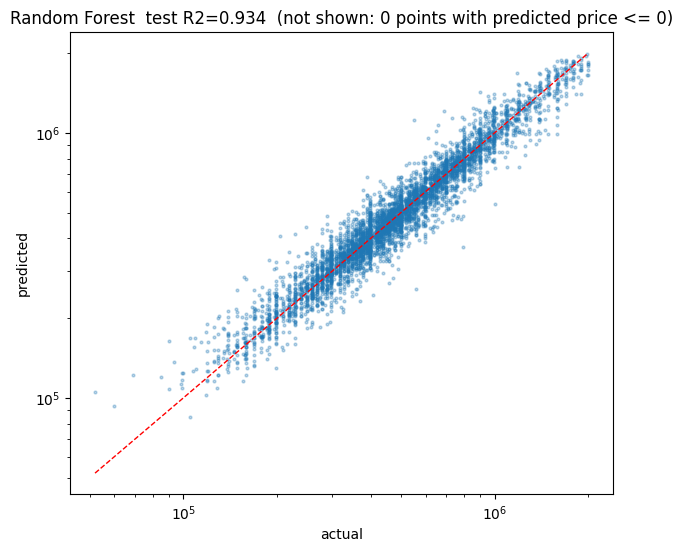

In [18]:
fig, ax = plt.subplots(figsize=(7, 6))
shown = test_pred > 0   # แกน log วาดค่าที่ <= 0 ไม่ได้
ax.scatter(y_test[shown], test_pred[shown], s=4, alpha=0.3)
price_range = [y_test.min(), y_test.max()]
ax.plot(price_range, price_range, "r--", lw=1)   # เส้นที่ทายถูกพอดี
ax.set(xscale="log", yscale="log", xlabel="actual", ylabel="predicted",
       title=f"Random Forest  test R2={r2_score(y_test, test_pred):.3f}  (not shown: {(~shown).sum()} points with predicted price <= 0)")
plt.show()

## 12. ตัวแปรไหนสำคัญ
- `built-in` = ค่าที่โมเดลคำนวณเอง (รวมคอลัมน์ dummy ของตัวแปรเดียวกัน) มักให้น้ำหนักเกินกับตัวแปรที่มีหลายค่า (`model` มี 118 ค่า)
- `permutation (val)` = สลับค่าของตัวแปรนั้นทั้งก้อนแบบสุ่มบน val แล้วดูว่า MAE แย่ลงแค่ไหน (น่าเชื่อถือกว่า)

In [19]:
builtin = pd.Series(best_model.feature_importances_, index=X_train.columns).groupby(owner).sum()   # รวมคอลัมน์ dummy ของตัวแปรเดียวกัน
rng = np.random.default_rng(SEED)
val_mae = np.abs(val_pred - y_val).mean()
perm = {}
for v in FEATURES:
    cols = [c for c in X_val.columns if owner(c) == v]
    gaps = []
    for _ in range(5):
        X_shuffled = X_val.copy()
        X_shuffled[cols] = X_shuffled[cols].values[rng.permutation(len(X_shuffled))]
        gaps.append(np.abs(best_model.predict(X_shuffled) - y_val).mean() - val_mae)
    perm[v] = np.mean(gaps)
importance = pd.DataFrame({"built-in": builtin.reindex(FEATURES), "permutation (val)": pd.Series(perm)})
importance = importance / importance.sum()   # ทำให้แต่ละคอลัมน์รวมกันได้ 1
importance.sort_values("permutation (val)", ascending=False).round(3)

,built-in,permutation (val)
engine_capacity,0.207,0.298
car_age,0.259,0.293
car_type,0.163,0.124
brand,0.132,0.113
model,0.132,0.078
mileage,0.065,0.047
fuel_type,0.021,0.022
gear_type,0.009,0.016
color,0.013,0.008


## 13. ทายพลาดตรงไหน (validation)
แยกตามอายุรถ และ 15 รุ่นที่พลาดมากที่สุด (เฉพาะรุ่นที่มีอย่างน้อย 10 คันใน val)

In [20]:
errors = val.copy()
errors["pred"] = val_pred
errors["abs_err"] = (errors["pred"] - errors["price"]).abs()   # พลาดกี่บาท
errors["ape"] = errors["abs_err"] / errors["price"]            # พลาดกี่ % ของราคา
errors["age_bin"] = pd.cut(errors["car_age"], [-1, 2, 5, 8, 12, 16, 20, 25])

by_age = errors.groupby("age_bin", observed=True).agg(
    n=("ape", "size"), MAE=("abs_err", "mean"), MAPE=("ape", "mean"))
display(by_age.round(3))

by_model = errors.groupby(["brand", "model"]).agg(
    n=("ape", "size"), MAE=("abs_err", "mean"), MAPE=("ape", "mean"), med_price=("price", "median"))
by_model = by_model[by_model["n"] >= 10]
by_model.sort_values("MAE", ascending=False).head(15).round(3)

,n,MAE,MAPE
age_bin,,,
"(-1, 2]",262,70104.131,0.082
"(2, 5]",1603,60503.616,0.091
"(5, 8]",1666,51439.251,0.095
"(8, 12]",989,43030.880,0.107
"(12, 16]",441,41055.802,0.165
"(16, 20]",93,36036.328,0.174


n         MAE   MAPE  med_price
brand         model                                      
MERCEDES-BENZ GLC220     10  180072.167  0.112  1645000.0
VOLKSWAGEN    CARAVELLE  14  144162.410  0.179   769000.0
MERCEDES-BENZ C220       27  141050.444  0.112  1390000.0
BMW           530E       25  133356.360  0.132   899000.0
              X3         24  131587.502  0.141  1032500.0
TOYOTA        VELLFIRE   39  127514.227  0.096  1379000.0
MERCEDES-BENZ E350       14  113093.661  0.153   749000.0
              E300       21  108942.340  0.114  1150000.0
              C300       14  107243.428  0.132   893500.0
TOYOTA        ALPHARD    55  102987.934  0.084  1599000.0
HYUNDAI       STARIA     20  101839.415  0.084  1084000.0
BMW           520D       23   99132.608  0.130   799000.0
MERCEDES-BENZ A200       12   94651.236  0.096   909000.0
BMW           330E       24   92084.860  0.097  1039000.0
MERCEDES-BENZ GLC250     20   91765.211  0.078  1149000.0